In [1]:
import itertools

import mrcfile
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, CenteredNorm

import numpy as np
# Align
from scipy.stats import linregress
from scipy.ndimage import fourier_gaussian

from mg_sampling import PROJECT_DIR
from mg_sampling.density.utils import get_map_params, voxels_around
from mg_sampling.tools import edges_to_range, range_to_edges

import MDAnalysis as mda

π = np.pi

/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
map = MRC(PROJECT_DIR / 'density/emd_42499.map')

In [51]:
Grid(map.array, map.edges).origin

array([0., 0., 0.])

Object `np.reshape` not found.


In [ ]:
from math import prod
import numpy as np

from gridData.mrc import MRC
from gridData import Grid
from mg_sampling import PROJECT_DIR

class SparseGrid(Grid):
    def __init__(self, vox_values, vox_indices, shape, origin=None, delta,
                 metadata=None):
        self.shape = shape
        self.vox_values = np.asanyarray(vox_values)
        self.vox_indices = np.asanyarray(vox_indices)
        self._grid = None

        if edges is not None:
            self.edges = edges
            self._update()
        elif origin is not None and delta is not None:
            # setup from generic data
            origin = numpy.asanyarray(origin)
            delta = numpy.asanyarray(delta)
            if len(origin) != grid.ndim:
                raise TypeError(
                    "Dimension of origin is not the same as grid dimension.")
            if delta.shape == () and numpy.isreal(delta):
                delta = numpy.ones(grid.ndim) * delta
            elif delta.ndim > 1:
                raise NotImplementedError(
                    "Non-rectangular grids are not supported.")
            elif len(delta) != grid.ndim:
                raise TypeError("delta should be scalar or array-like of"
                                "len(grid.ndim)")
            # note that origin is CENTER so edges must be shifted by -0.5*delta
            self.edges = [origin[dim] +
                          (numpy.arange(m + 1) - 0.5) * delta[dim]
                          for dim, m in enumerate(grid.shape)]
            self.grid = numpy.asanyarray(grid)
            self._update()
        else:
            raise ValueError(
                "Wrong/missing data to set up Grid. Use Grid() or "
                "Grid(grid=<array>, edges=<list>) or "
                "Grid(grid=<array>, origin=(x0, y0, z0), delta=(dx, dy, dz)):\n"
                "grid={0} edges={1} origin={2} delta={3}".format(
                    grid, edges, origin, delta))
    @property
    def grid(self):
        """Return (dense) grid array. The result is cached."""
        if self._grid is None:
            array = np.zeros(self.size, dtype=self.vox_values.dtype)
            array[self.vox_indices] = self.vox_values
            self._grid = np.reshape(array, self.shape, order='F')
        return self._grid

    @property
    def size(self):
        return prod(self.shape)


        

In [47]:
data = MRC(PROJECT_DIR / 'density/emd_42499.map')
data = Grid(data.array, data.edges)
shape = data.grid.shape
array = data.grid.flatten(order='F')
vox_indices = np.nonzero(array)
vox_values = array[vox_indices]
data = SparseGrid(vox_values, vox_indices, shape)

In [49]:
data.delta

AttributeError: 'SparseGrid' object has no attribute 'delta'

In [3]:
import numpy

In [7]:
array_api_compat.array_namespace(numpy.array(None))

<module 'array_api_compat.numpy' from '/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/array_api_compat/numpy/__init__.py'>

In [13]:
import torch
xp = array_api_compat.array_namespace(torch.empty(0))

In [16]:
xp.asarray([1], copy=True)

tensor([1])

In [5]:
emds = ['emd_42499', 'emd_31385']

sharpening_factors = {
    'emd_42499': -79.23,
    'emd_31385': -14,
}

ref_maps = {}
ref_map_params = {}

for emd in emds:
    path = PROJECT_DIR / f'density/{emd}.map'
    with mrcfile.open(path, permissive=True) as mrc:
        ref_map_params[emd] = get_map_params(mrc)

        # mrcfile follows the Python / C-style convention for axis ordering. 
        # This means that the first index is the slowest axis (typically Z for volume data or Y for images) 
        # and the last index is the fastest axis (typically X), and the numpy arrays are C-contiguous:

        # data = mrcfile.read('tmp.mrc')

        # data
        # array([[ 0,  1,  2,  3],
        #        [ 4,  5,  6,  7],
        #        [ 8,  9, 10, 11]], dtype=int8)

        # data[1, 0]  # x = 0, y = 1
        # 4

        # data[2, 3]  # x = 3, y = 2
        # 11

        # data.flags.c_contiguous
        # True

        # data.flags.f_contiguous
        # False

        ref_data = mrc.data.copy()  # ref_data[a, b, c] -> S = a, R = b, C = c
        # Here C = columns, R = rows, S = sections
        # The MRC format allows to map C, R, S to physical axes X, Y, Z
        # Usually C, R, S -> X, Y, Z but not always
        # ref_data = ref_data.transpose((2, 1, 0))  # more intuitive order ref_data[C, R, S]
        order = np.argsort(ref_map_params[emd]['filemap'])  # find order to have X, Y, Z
        ref_data.transpose(order)
        ref_maps[emd] = ref_data

# Map unsharpening
# Smoothing by a factor σ: convolution with gaussian g(x) = (σ*sqrt(2π))⁻¹ exp[-x²/(2σ²)]
# Equivalent to multiplying in fourier space with G(k) = exp[-2π²k²σ²]

for emd in emds:
    fft_map = np.fft.fftn(ref_maps[emd])
    freqs = [np.fft.fftfreq(n, d=dx) for n, dx in zip(ref_map_params[emd]['nbin'], ref_map_params[emd]['dx'])]  # Å⁻¹
    kx, ky, kz = np.meshgrid(*freqs, indexing='ij')
    k2 = kx**2 + ky**2 + kz**2  # Å⁻²
    kernel = np.exp(k2 * sharpening_factors[emd] / 4)
    fft_map_smooth = fft_map * kernel
    data_smooth = np.real(np.fft.ifftn(fft_map_smooth)).astype(np.float32)

    ref_maps[f'{emd}_unsharp'] = data_smooth

In [10]:
import mrcfile
import numpy as np

in_file = 'map.mrc'
out_file = 'map_unsharpened.mrc'
sharpening_factor = -79.23  # Negative means unsharpening = blurring

def get_map_params(mrc):
    return {
        "map": [ 
            int(mrc.header.mapc),
            int(mrc.header.mapr),
            int(mrc.header.maps),
        ],  # data organization, 1 for x, 2 for y, 3 for z
        "nbin": [int(mrc.header.nx), int(mrc.header.ny), int(mrc.header.nz)],
        "nbin_tot": int(mrc.header.nx * mrc.header.ny * mrc.header.nz),
        "x0": [
            float(mrc.header.origin.x + float(mrc.header.nxstart) * mrc.voxel_size.x),
            float(mrc.header.origin.y + float(mrc.header.nystart) * mrc.voxel_size.y),
            float(mrc.header.origin.z + float(mrc.header.nzstart) * mrc.voxel_size.z),
        ],
        # dimension of one voxel the in x, y, z directions
        "dx": [
            float(mrc.voxel_size.x),
            float(mrc.voxel_size.y),
            float(mrc.voxel_size.z),
        ],
    }

with mrcfile.open(in_file) as mrc:
    map_params = get_map_params(mrc)
    data = mrc.data.copy()

# Ensure axes correspond to [x, y, z]
# map_params['map'] has directions corresponding to columns, rows, sections [c, r, s] with 1 = x, 2 = y, 3 = z.
# NumPy convention is row-major order (C-order), so data has shape [s, r, c].
order = np.argsort(map_params['map'][::-1])
data = data.transpose(order)

# Map unsharpening
# Smoothing by a factor σ is a convolution with gaussian g(x) = (σ*sqrt(2π))⁻¹ exp[-x²/(2σ²)]
# Equivalently this is multiplication in Fourier space with G(k) = exp[-2π²k²σ²]
# For B-factors this is G(k) = exp[-Bk²/4] where k is spatial frequency (Å⁻¹) and B has units of Å²
fft_data = np.fft.fftn(data)
freqs = [np.fft.fftfreq(n, d=dx) for n, dx in zip(map_params['nbin'], map_params['dx'])]  # Å⁻¹
kx, ky, kz = np.meshgrid(*freqs, indexing='ij')
k2 = kx**2 + ky**2 + kz**2  # Å⁻²
kernel = np.exp(k2 * sharpening_factor / 4)
fft_data = fft_data * kernel
data = np.real(np.fft.ifftn(fft_data)).astype(np.float32)

data = data.transpose((2, 1, 0))  # Back to [z, y, x]
with mrcfile.new(out_file, overwrite=True) as mrc:
    mrc.set_data(data)
    mrc.voxel_size = map_params["dx"]


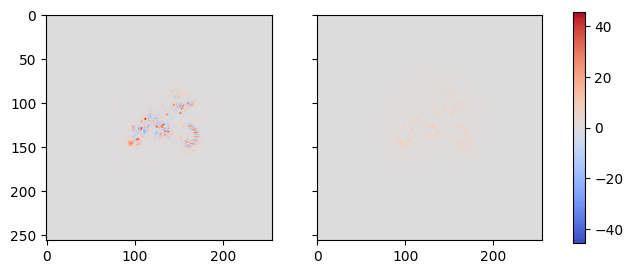

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm

fig, (ax1, ax2) = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(8, 3))
norm = CenteredNorm()
cmap = 'coolwarm'

with mrcfile.open(in_file) as mrc:
    map_params = get_map_params(mrc)
    data = mrc.data.copy()
order = np.argsort(map_params['map'][::-1])
data = data.transpose(order)

im = ax1.imshow(data[len(data)//2, :, :], norm=norm, cmap=cmap)

with mrcfile.open(out_file) as mrc:
    map_params = get_map_params(mrc)
    data = mrc.data.copy()
order = np.argsort(map_params['map'][::-1])
data = data.transpose(order)

ax2.imshow(data[len(data)//2, :, :], norm=norm, cmap=cmap)

plt.colorbar(im, ax=(ax1, ax2))

In [4]:
import numpy as np
np.argsort([1, 2, 3], reversed=True)

TypeError: argsort() got an unexpected keyword argument 'reversed'

In [6]:
def indices_to_mask(vox_indices, map_params):
    i, j, k = np.unravel_index(vox_indices, map_params['nbin'], order='F')
    mask = np.zeros(map_params['nbin'], dtype=bool)
    mask[i, j, k] = True
    return mask

u = mda.Universe(PROJECT_DIR / 'density/9cbu.pdb', guess_bonds=True, vdwradii={'Mg': 1.73})

# Voxel selection
vox_indices = voxels_around(
    u.select_atoms('not type H and nucleic'),
    5,
    ref_map_params,
)

vox_indices_rna = voxels_around(
    u.select_atoms('not type H and nucleic'),
    1.8,
    ref_map_params,
)

mask = indices_to_mask(vox_indices, ref_map_params)
mask_rna = indices_to_mask(vox_indices_rna, ref_map_params)
mask_shell = mask & ~mask_rna


/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/core/universe.py:607: DeprecationWarning: Bond guessing through the `guess_bonds` keyword is deprecated and will be removed in MDAnalysis 3.0. Instead, pass 'bonds', 'angles', and 'dihedrals' to the `to_guess` keyword in Universe for guessing these if they are not present, or `force_guess` if they are and you wish to replace these bonds with guessed values. The kwargs `fudge_factor`, `vdwradii`, and `lower_bound` are also deprecated and will be removed in MDAnalysis 3.0, where they should be passed into the Context for guessing on Universe instantiation. If using guess_TopologyAttrs, pass these kwargs to the method instead, as they will override the prev

KeyError: 'x0'

In [217]:
import numpy as np
      
def flatmap_to_dense(flatmap, vox_indices, map_params):      
    map = np.zeros(map_params['nbin_tot'], dtype=flatmap.dtype)      
    map[vox_indices] = flatmap      
    return map.reshape(map_params['nbin'], order='F') 

flatmap = np.array([0.2, 0.3, 0.4, 0.2])
vox_indices = np.array([1, 6, 8, 9])
mask_to_indices(flatmap_to_dense(flatmap, vox_indices, ref_map_params) != 0)

(array([1, 6, 8, 9]),)

In [101]:
local_shell_masks = [
    indices_to_mask(voxels_around([p], 5, ref_map_params), ref_map_params) & mask_shell
    for p in u.select_atoms('name P')
]

In [166]:
ATOM_COLORS = {'H': 'white', 'C': 'darkgray', 'N': 'blue', 'O': 'red', 'P': 'orange', 'Mg': 'pink'}
def plot_atomgroup(ag, dims=(0, 1), ax=None):
    ax = plt.gca() if ax is None else ax
    ix, iy = dims
    colors = [ATOM_COLORS[a.type] for a in ag]
    ax.scatter(ag.positions[:, ix], ag.positions[:, iy], c=colors)
    for (a, b) in ag.bonds:
        ax.plot(
            [a.position[ix], b.position[ix]],
            [a.position[iy], b.position[iy]],
            color='gray',
        )

(88.0770034790039, 108.0770034790039)

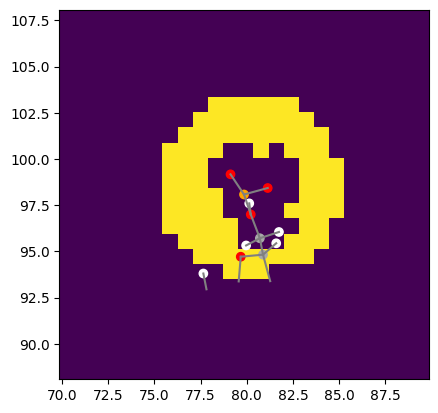

In [177]:
resindex = 0
ix, iy = (1, 2)

fig, ax = plt.subplots()

p = u.select_atoms(f'name P and resindex {resindex}')[0]
i, j, k = (p.position // np.asarray(ref_map_params['dx'])).astype(int)
L = ref_map_params['nbin'][0] * ref_map_params['dx'][0]
extent = [0, L, 0, L]

sel = tuple(slice(None) if d in (ix, iy) else ind for d, ind in enumerate((i, j, k)))

ax.imshow(local_shell_masks[resindex][sel].T, origin='lower', extent=extent)
plot_atomgroup(u.select_atoms(f'name P and resindex {resindex} or around 5 name P and resindex {resindex}'), dims=(ix, iy))

ax.set_xlim(p.position[ix] - 10, p.position[ix] + 10)
ax.set_ylim(p.position[iy] - 10, p.position[iy] + 10)


In [218]:
plt.scatter?

Signature:
plt.scatter(
    x: 'float | ArrayLike',
    y: 'float | ArrayLike',
    s: 'float | ArrayLike | None' = None,
    c: 'ArrayLike | Sequence[ColorType] | ColorType | None' = None,
    *,
    marker: 'MarkerType | None' = None,
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    alpha: 'float | None' = None,
    linewidths: 'float | Sequence[float] | None' = None,
    edgecolors: "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None" = None,
    colorizer: 'Colorizer | None' = None,
    plotnonfinite: 'bool' = False,
    data=None,
    **kwargs,
) -> 'PathCollection'
Docstring:
A scatter plot of *y* vs. *x* with varying marker size and/or color.

Parameters
----------
x, y : float or array-like, shape (n, )
    The data positions.

s : float or array-like, shape (n, ), optional
    The marker size in points**2 (typographic points are 1/72 in.).
    Default is ``rc

In [83]:
methods = ['plain_md', 'replex']
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p']
replicates = ['', '_0', '_1']
alignments = ['global', 'residue']
rnas = ['all']

maps = {}

for method, system, forcefield, replicate, alignment, rna in itertools.product(
    methods, systems, forcefields, replicates, alignments, rnas):
    path = PROJECT_DIR / f'density/{method}_{system}_{forcefield}{replicate}/aligned_{alignment}/{rna}.mrc'
    try:
        with mrcfile.open(path, permissive=True) as mrc:
            map_params = get_map_params(mrc)
            # order = np.argsort(map_params['filemap'])
            data = mrc.data.transpose((2, 1, 0)).copy()
            maps[f'{method}_{system}_{forcefield}{replicate}_{alignment}_{rna}'] = data
    except FileNotFoundError as e:
        print("Skip:", path)
    

Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_mMg_tip3p_0/aligned_global/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_mMg_tip3p_0/aligned_residue/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_mMg_tip3p_1/aligned_global/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_mMg_tip3p_1/aligned_residue/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_nMg_tip3p_0/aligned_global/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_nMg_tip3p_0/aligned_residue/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_nMg_tip3p_1/aligned_global/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_nMg_tip3p_1/aligned_residue/all.mrc
Skip: /leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/density/plain_md_7ez0_noion_mMg_tip3p/aligned

In [75]:
maps.keys()

dict_keys(['plain_md_7ez0_mMg_tip3p_global_all', 'plain_md_7ez0_mMg_tip3p_residue_all', 'plain_md_7ez0_nMg_tip3p_global_all', 'replex_7ez0_mMg_tip3p_0_global_all', 'replex_7ez0_mMg_tip3p_0_residue_all', 'replex_7ez0_mMg_tip3p_1_global_all', 'replex_7ez0_mMg_tip3p_1_residue_all'])

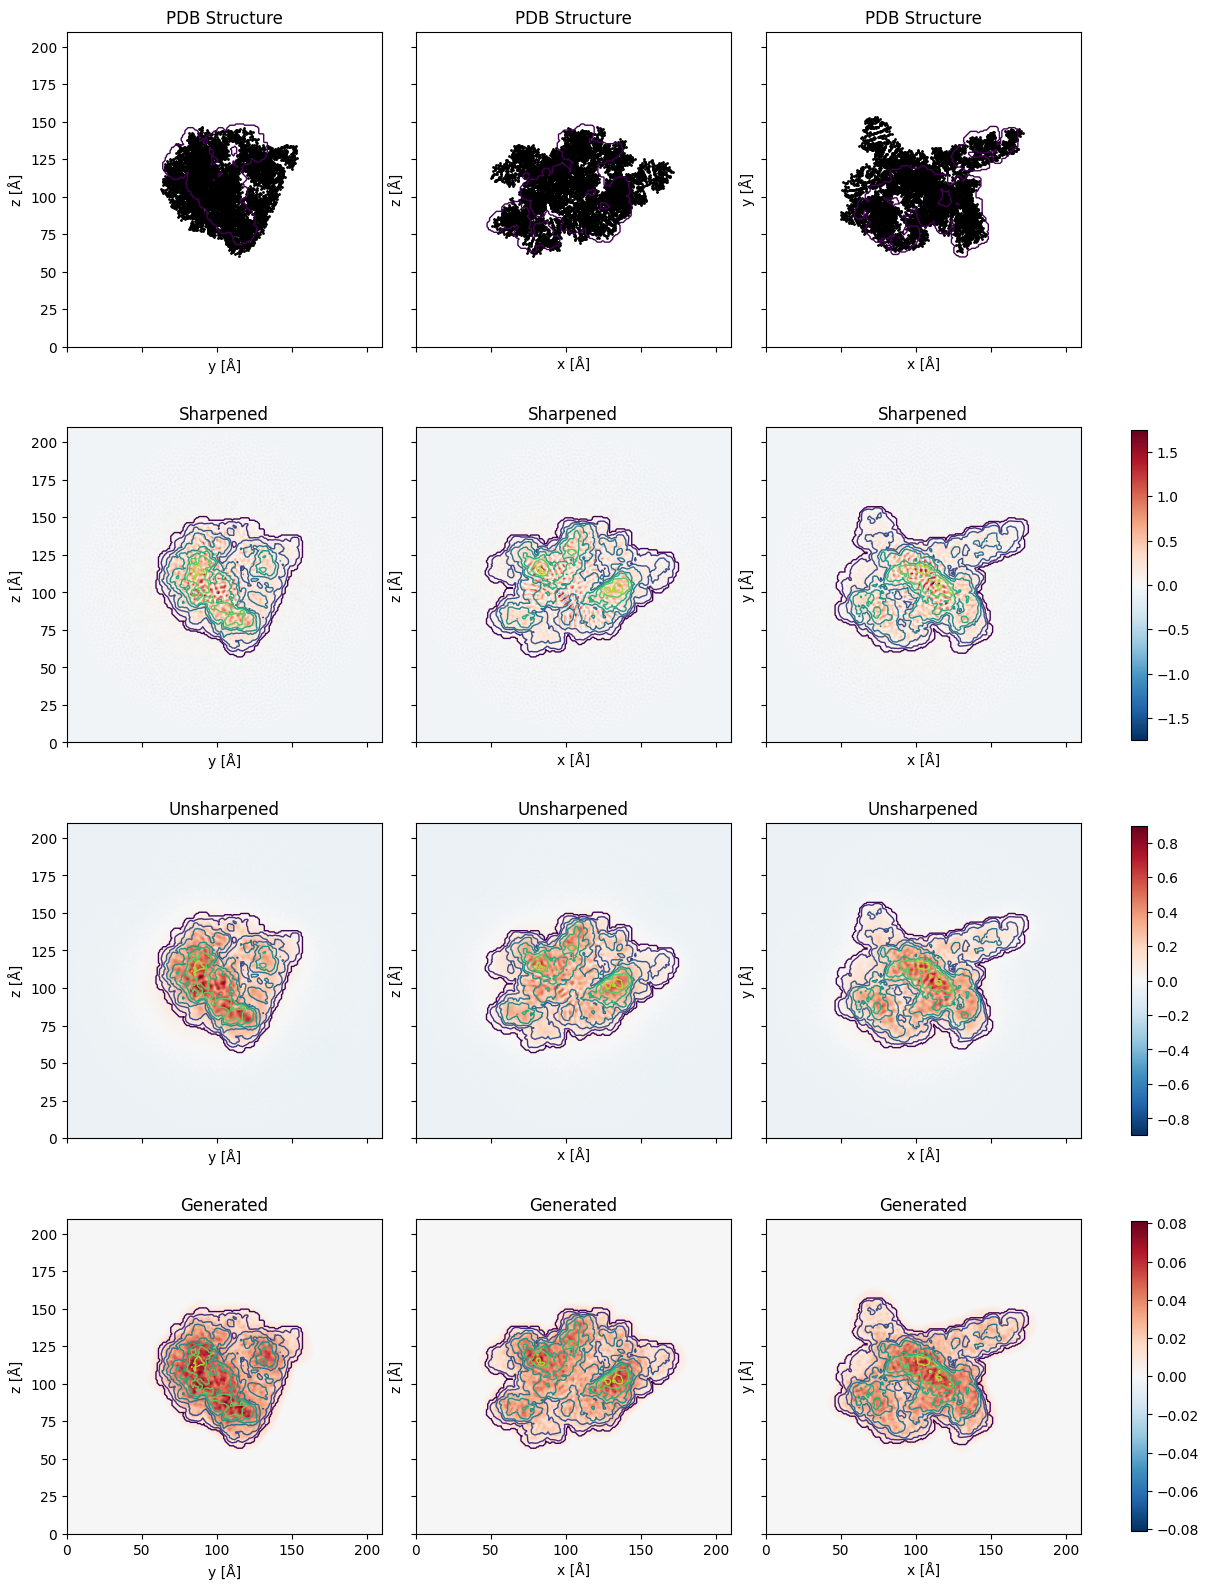

In [76]:
fig, axarr = plt.subplots(ncols=3, nrows=4, figsize=(12, 16), sharey=True, sharex=True, layout="constrained")

n = ref_map_params['nbin'][0]
dx = ref_map_params['dx'][0]
L = n * dx
extent = [0, L, 0, L]
norm_a = CenteredNorm()
norm_b = CenteredNorm()
norm_c = CenteredNorm()
cmap = 'RdBu_r'
rna = u.select_atoms('not type H and nucleic')
dims = ['x', 'y', 'z']

for i in range(3):
    ax = axarr[0, i]
    ix, iy = tuple(j for j in range(3) if j != i)
    sel = tuple(slice(None) if j != i else n // 2 for j in range(3))
    ax.scatter(rna.positions[:, ix], rna.positions[:, iy], c='k', s=1)
    ax.set_aspect(1)
    ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
    ax.set_xlabel(f'{dims[ix]} [Å]')
    ax.set_ylabel(f'{dims[iy]} [Å]')
    ax.set_title('PDB Structure')

    ax = axarr[1, i]
    _proj_map = ref_maps['sharp'].mean(axis=i)
    im = ax.imshow(_proj_map.T, origin='lower', norm=norm_a, cmap=cmap, extent=extent)
    ax.contour(mask.mean(axis=i).T, origin='lower', extent=extent, linewidths=1)
    ax.set_xlabel(f'{dims[ix]} [Å]')
    ax.set_ylabel(f'{dims[iy]} [Å]')
    ax.set_title('Sharpened')
    if i == 2:
        plt.colorbar(im, ax=axarr[1,:], shrink=0.8)


    ax = axarr[2, i]
    _proj_map = ref_maps['unsharp'].mean(axis=i)
    im = ax.imshow(_proj_map.T, origin='lower', norm=norm_b, cmap=cmap, extent=extent)
    ax.contour(mask.mean(axis=i).T, origin='lower', extent=extent, linewidths=1)
    ax.set_xlabel(f'{dims[ix]} [Å]')
    ax.set_ylabel(f'{dims[iy]} [Å]')
    ax.set_title('Unsharpened')
    if i == 2:
        plt.colorbar(im, ax=axarr[2,:], shrink=0.8)

    ax = axarr[3, i]
    _proj_map = maps['plain_md_7ez0_nMg_tip3p_global_all'].mean(axis=i)
    im = ax.imshow(_proj_map.T, origin='lower', norm=norm_c, cmap=cmap, extent=extent)
    ax.contour(mask.mean(axis=i).T, origin='lower', extent=extent, linewidths=1)
    ax.set_xlabel(f'{dims[ix]} [Å]')
    ax.set_ylabel(f'{dims[iy]} [Å]')
    ax.set_title('Generated')
    if i == 2:
        plt.colorbar(im, ax=axarr[3,:], shrink=0.8)


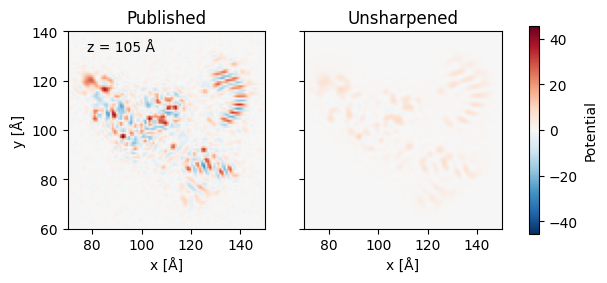

In [26]:
fig, axarr = plt.subplots(ncols=2, figsize=(7, 3), sharey=True, sharex=True)
n = ref_map_params['nbin'][0]
L = n * ref_map_params['dx'][0]
extent = [0, L, 0, L]
sel = np.s_[:, :, n // 2]
norm = CenteredNorm()
cmap = 'RdBu_r'

ax = axarr[0]
im = ax.imshow(ref_maps['sharp'][sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.set_xlabel('x [Å]')
ax.set_ylabel('y [Å]')
ax.text(0.1, 0.9, f'z = {L/2:.0f} Å', transform=ax.transAxes)
ax.set_title('Published')
plt.colorbar(im, ax=axarr, label='Potential', shrink=0.9)

ax = axarr[1]
ax.imshow(ref_maps['unsharp'][sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.set_xlabel('x [Å]')
ax.set_title('Unsharpened')

ax.set_xlim(70, 150)
ax.set_ylim(60, 140)


plt.savefig('figures/map_sharpening.pdf')

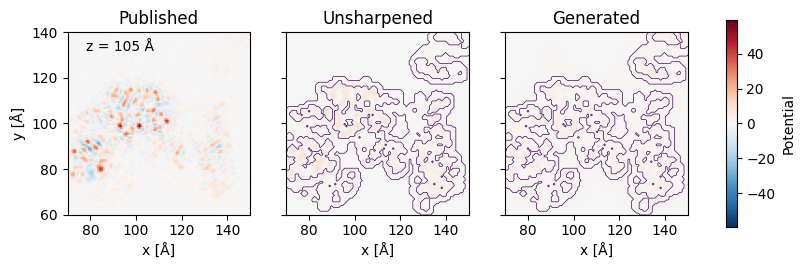

In [68]:
fig, axarr = plt.subplots(ncols=3, figsize=(10, 3), sharey=True, sharex=True)
n = ref_map_params['nbin'][0]
L = n * ref_map_params['dx'][0]
extent = [0, L, 0, L]
sel = np.s_[:, :, n // 2]
norm = CenteredNorm()
cmap = 'RdBu_r'

ax = axarr[0]
im = ax.imshow(ref_maps['sharp'][sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.set_xlabel('x [Å]')
ax.set_ylabel('y [Å]')
ax.text(0.1, 0.9, f'z = {L/2:.0f} Å', transform=ax.transAxes)
ax.set_title('Published')
plt.colorbar(im, ax=axarr, label='Potential', shrink=0.9)

ax = axarr[1]
ax.imshow(ref_maps['unsharp'][sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.contour(mask_shell[sel].T, origin='lower', extent=extent, linewidths=0.5, linestyles='solid')
ax.set_xlabel('x [Å]')
ax.set_title('Unsharpened')

ax = axarr[2]
data = maps['replex_7ez0_mMg_tip3p_0_residue_all']
slope, intercept, r_value, p_value, std_err = linregress(data[mask], ref_maps['unsharp'][mask])
data = slope * data + intercept
ax.imshow(data[sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=0.5, linestyles='dashed')
ax.contour(mask_shell[sel].T, origin='lower', extent=extent, linewidths=0.5, linestyles='solid')
ax.set_xlabel('x [Å]')
ax.set_title('Generated')

ax.set_xlim(70, 150)
ax.set_ylim(60, 140)


plt.savefig('figures/map_sharpening_vs_generated.pdf')

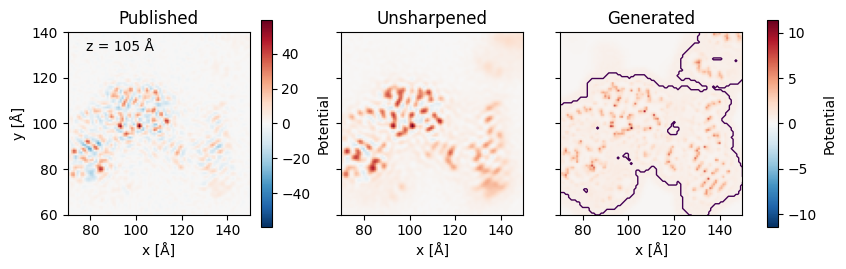

In [29]:
fig, axarr = plt.subplots(ncols=3, figsize=(10, 3), sharey=True, sharex=True)
n = ref_map_params['nbin'][0]
L = n * ref_map_params['dx'][0]
extent = [0, L, 0, L]
sel = np.s_[:, :, n // 2]
cmap = 'RdBu_r'

ax = axarr[0]
im = ax.imshow(ref_maps['sharp'][sel].T, origin='lower', norm=CenteredNorm(), cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.set_xlabel('x [Å]')
ax.set_ylabel('y [Å]')
ax.text(0.1, 0.9, f'z = {L/2:.0f} Å', transform=ax.transAxes)
ax.set_title('Published')
plt.colorbar(im, ax=ax, label='Potential', shrink=0.9)

norm = CenteredNorm()

ax = axarr[1]
im = ax.imshow(ref_maps['unsharp'][sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
# ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.set_xlabel('x [Å]')
ax.set_title('Unsharpened')

ax = axarr[2]
data = maps['replex_7ez0_mMg_tip3p_0_residue_all']
slope, intercept, r_value, p_value, std_err = linregress(data[mask], ref_maps['unsharp'][mask])
data = slope * data + intercept
ax.imshow(data[sel].T, origin='lower', norm=norm, cmap=cmap, extent=extent)
ax.contour(mask[sel].T, origin='lower', extent=extent, linewidths=1)
ax.set_xlabel('x [Å]')
ax.set_title('Generated')

plt.colorbar(im, ax=axarr[1:], label='Potential', shrink=0.9)

ax.set_xlim(70, 150)
ax.set_ylim(60, 140)


plt.savefig('figures/map_sharpening_vs_generated.pdf')

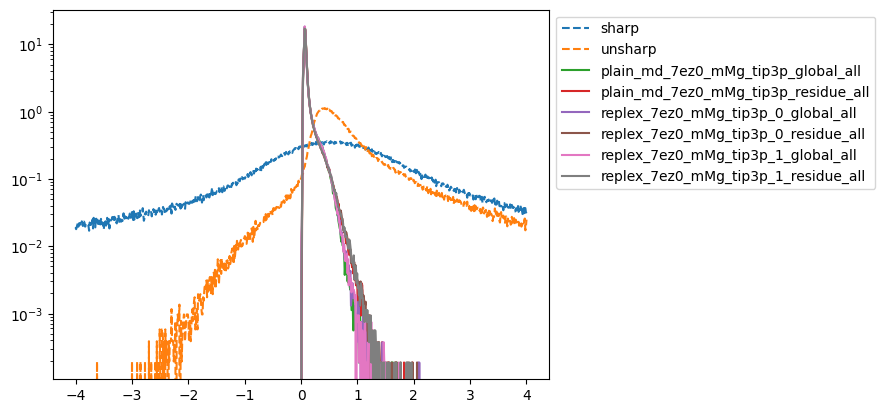

In [30]:
fig, ax = plt.subplots()
vrange = np.linspace(-4, 4, 800)

for k in ref_maps:
    data = ref_maps[k]
    p, _ = np.histogram(data[mask].flatten(), bins=range_to_edges(vrange), density=True)
    ax.plot(vrange, p, label=k, ls='dashed')

for k in maps:
    data = maps[k]
    p, _ = np.histogram(data[mask].flatten(), bins=range_to_edges(vrange), density=True)
    ax.plot(vrange, p, label=k)

ax.set_yscale('log')
ax.legend(bbox_to_anchor=(1, 1))

In [84]:
cc_sharp = {}

for k, data in maps.items():
    for sharp in ('sharp',):
        res = linregress(data[mask], ref_maps[sharp][mask])
        cc_sharp[f'{k}_{sharp}'] = res.rvalue
        res = linregress(data[mask_shell], ref_maps[sharp][mask_shell])
        cc_sharp[f'{k}_{sharp}_shell'] = res.rvalue
        res = linregress(data[mask_rna], ref_maps[sharp][mask_rna])
        cc_sharp[f'{k}_{sharp}_rna'] = res.rvalue

cc_unsharp = {}

for k, data in maps.items():
    for sharp in ('unsharp',):
        res = linregress(data[mask], ref_maps[sharp][mask])
        cc_unsharp[f'{k}_{sharp}'] = res.rvalue
        res = linregress(data[mask_shell], ref_maps[sharp][mask_shell])
        cc_unsharp[f'{k}_{sharp}_shell'] = res.rvalue
        res = linregress(data[mask_rna], ref_maps[sharp][mask_rna])
        cc_unsharp[f'{k}_{sharp}_rna'] = res.rvalue

In [85]:
for k, v in sorted(cc_unsharp.items(), key=lambda item: item[1]):
    print(k, v)

replex_7ez0_mMg_tip3p_0_residue_all_unsharp_shell 0.2843082273327846
replex_7ez0_mMg_tip3p_0_global_all_unsharp_shell 0.2870797052676608
replex_7ez0_mMg_tip3p_1_residue_all_unsharp_shell 0.28999869652986715
replex_7ez0_mMg_tip3p_1_global_all_unsharp_shell 0.294477195666821
plain_md_7ez0_mMg_tip3p_global_all_unsharp_shell 0.2960675282037513
plain_md_7ez0_nMg_tip3p_global_all_unsharp_shell 0.30018796584195395
plain_md_7ez0_mMg_tip3p_residue_all_unsharp_shell 0.30225615858522115
plain_md_7ez0_nMg_tip3p_residue_all_unsharp_shell 0.30701924160581423
replex_7ez0_mMg_tip3p_0_global_all_unsharp_rna 0.5444344798184397
replex_7ez0_mMg_tip3p_1_global_all_unsharp_rna 0.5502421491026007
plain_md_7ez0_mMg_tip3p_global_all_unsharp_rna 0.5538509377131948
plain_md_7ez0_nMg_tip3p_global_all_unsharp_rna 0.5565588176015372
replex_7ez0_mMg_tip3p_0_residue_all_unsharp_rna 0.6108305620374261
replex_7ez0_mMg_tip3p_1_residue_all_unsharp_rna 0.6110408476176014
replex_7ez0_mMg_tip3p_0_global_all_unsharp 0.617501

## One slice

In [33]:
data = maps['replex_7ez0_mMg_tip3p_0_residue_all']
mask = (data > 0)

slope, intercept, r_value, p_value, std_err = linregress(data[mask], ref_maps['unsharp'][mask])
fit_data_unsharp = slope * data + intercept

slope, intercept, r_value, p_value, std_err = linregress(data[mask], ref_maps['sharp'][mask])
fit_data_sharp = slope * data + intercept

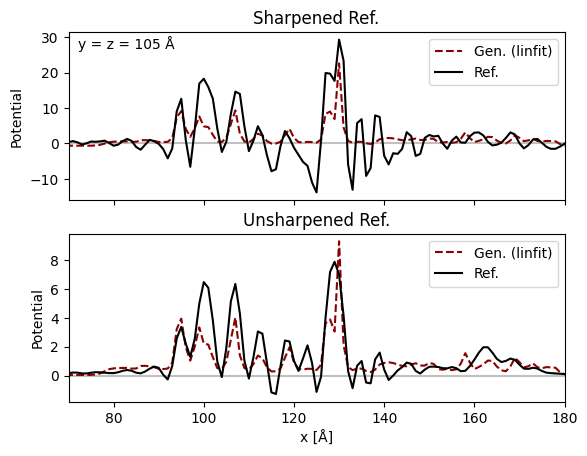

In [34]:
fig, axarr = plt.subplots(nrows=2, sharey=False, sharex=True)

i, j = data.shape[0] // 2, data.shape[1] // 2

s = np.s_[:, i, j]
ax = axarr[0]
ax.text(0.02, 0.9, f"y = z = {L/2:.0f} Å", transform=ax.transAxes)
ax.axhline([0], color='silver')
ax.plot(fit_data_sharp[s], label='Gen. (linfit)', color='darkred', ls='dashed')
ax.plot(ref_maps['sharp'][s], label='Ref.', color='black')
ax.set_ylabel("Potential")
ax.set_title("Sharpened Ref.")
ax.legend()
ax = axarr[1]
ax.axhline([0], color='silver')
ax.plot(fit_data_unsharp[s], label='Gen. (linfit)', ls='dashed', color='darkred')
ax.plot(ref_maps['unsharp'][s], label='Ref.', color='black')
ax.set_xlabel("x [Å]")
ax.set_ylabel("Potential")
ax.set_title("Unsharpened Ref.")
ax.legend()

ax.set_xlim(70, 180)
plt.savefig("figures/one_dimensional_slice_gen_vs_sharpening.pdf")

100%|██████████| 20/20 [00:39<00:00,  1.97s/it]


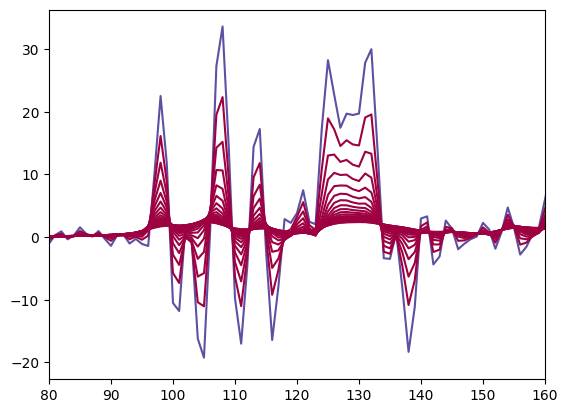

In [31]:
from tqdm import tqdm

data = maps['replex_7ez0_mMg_tip3p_0_residue_all']
ref_data = ref_maps['sharp']

b_factors = np.linspace(0, 4 * b_factor, 20)
r_values = []

fig, ax = plt.subplots()
cm = plt.cm.Spectral_r

for B in tqdm(b_factors):
    fft_map = np.fft.fftn(ref_data)
    freqs = [np.fft.fftfreq(n, d=dx) for n, dx in zip(map_params['nbin'], map_params['dx'])]  # Å⁻¹
    kx, ky, kz = np.meshgrid(*freqs, indexing='ij')
    k2 = kx**2 + ky**2 + kz**2  # Å⁻²
    kernel = np.exp(- B * k2 / 4)
    fft_map_smooth = fft_map * kernel
    _ref_data_smooth = np.real(np.fft.ifftn(fft_map_smooth)).astype(np.float32)

    slope, intercept, r_value, p_value, std_err = linregress(data[mask], _ref_data_smooth[mask])
    r_values.append(r_value)

    i, j = data.shape[0] // 2, data.shape[1] // 2

    s = np.s_[i, j, :]


    ax.plot(_ref_data_smooth[s], color=cm(B / 4 * b_factor))
    # ax.plot(_fit_data_smooth[s], label='gen (linfit to unsharp)', ls='dashed', color=l.get_color())

    plt.xlim(80, 160)




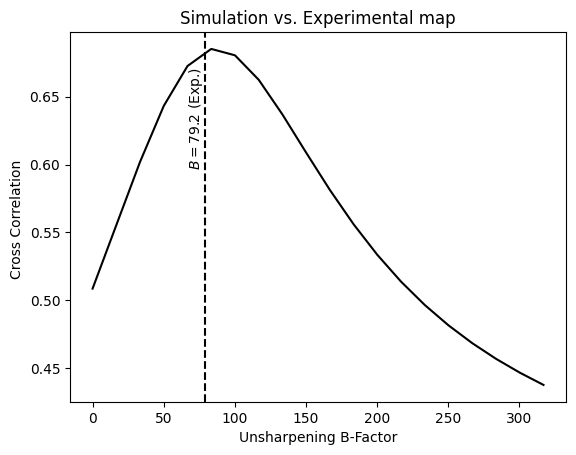

In [32]:
fig, ax = plt.subplots()

ax.plot(b_factors, r_values, color='black')
ax.axvline([b_factor], color='black', ls='dashed')
ax.text(b_factor, 0.6, f'$B = {b_factor:.1f}$ (Exp.)', rotation=90, ha='right')
ax.set_xlabel(r"Unsharpening B-Factor")
ax.set_ylabel("Cross Correlation ")
ax.set_title("Simulation vs. Experimental map")
plt.savefig("figures/cross_correlation_vs_sharpening.pdf")

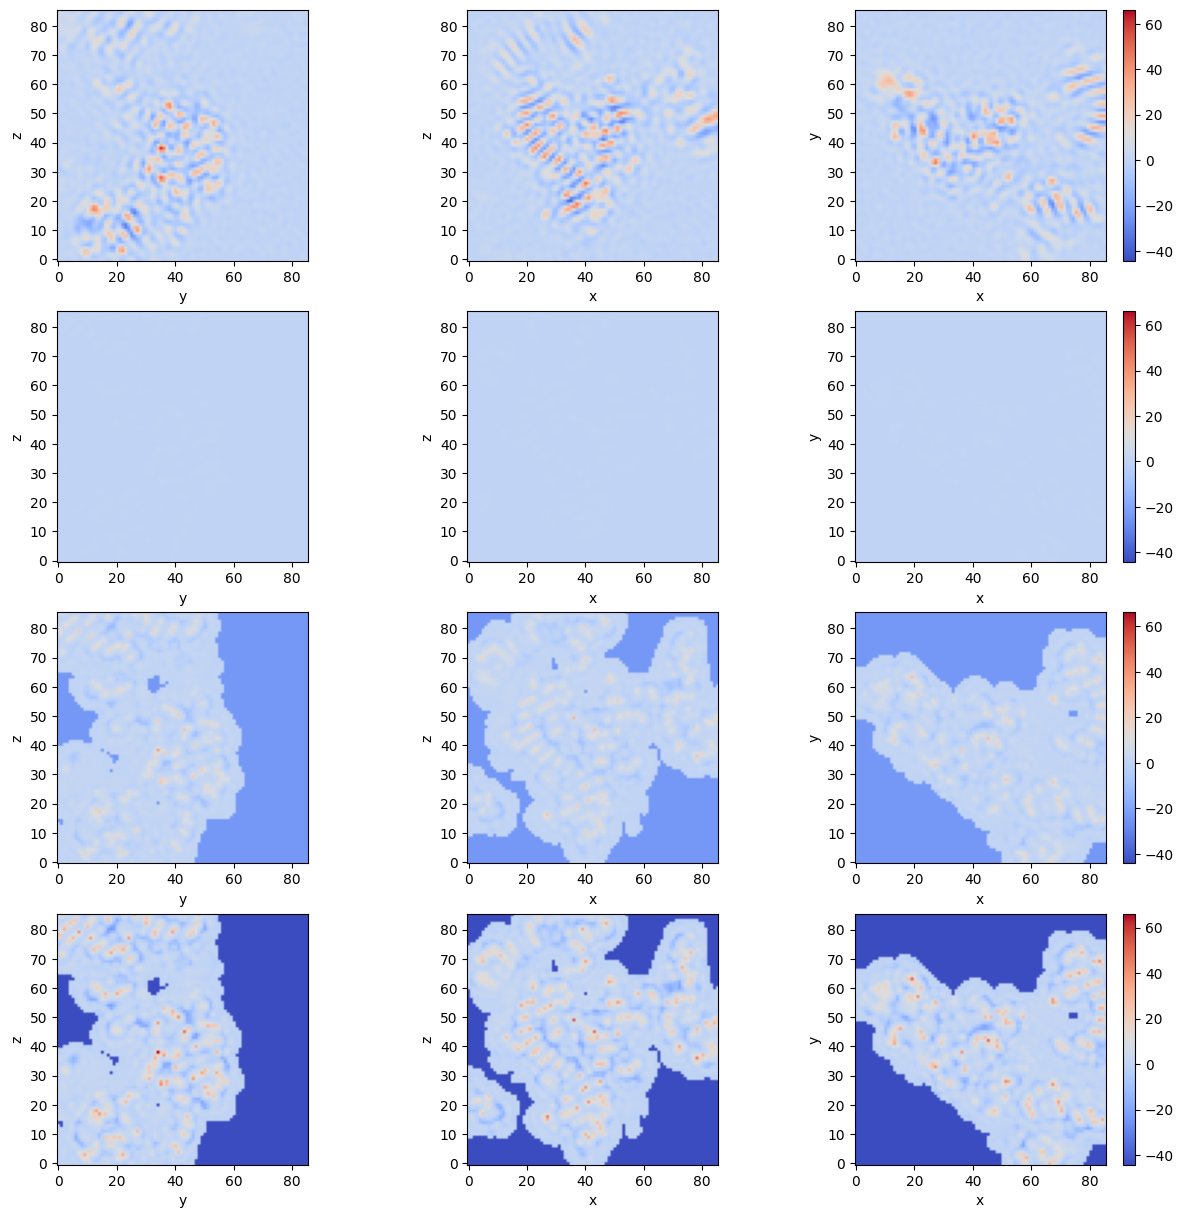

In [10]:
fig, axarr = plt.subplots(ncols=3, nrows=4, figsize=(15, 15))

norm = Normalize(vmin=ref_data[mask].min(), vmax=ref_data[mask].max())
for i, d in enumerate((ref_data, data, fit_data, norm_data)):
    s = len(d) // 2
    a = len(d) // 3
    ax = axarr[i, 0]
    ax.imshow(d[s, a:-a, a:-a].T, origin='lower', cmap='coolwarm', norm=norm)
    ax.set_xlabel('y')
    ax.set_ylabel('z')
    ax = axarr[i, 1]
    ax.imshow(d[a:-a, s, a:-a].T, origin='lower', cmap='coolwarm', norm=norm)
    ax.set_xlabel('x')
    ax.set_ylabel('z')
    ax = axarr[i, 2]
    im = ax.imshow(d[a:-a, a:-a, s].T, origin='lower', cmap='coolwarm', norm=norm)
    plt.colorbar(im, ax=ax)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

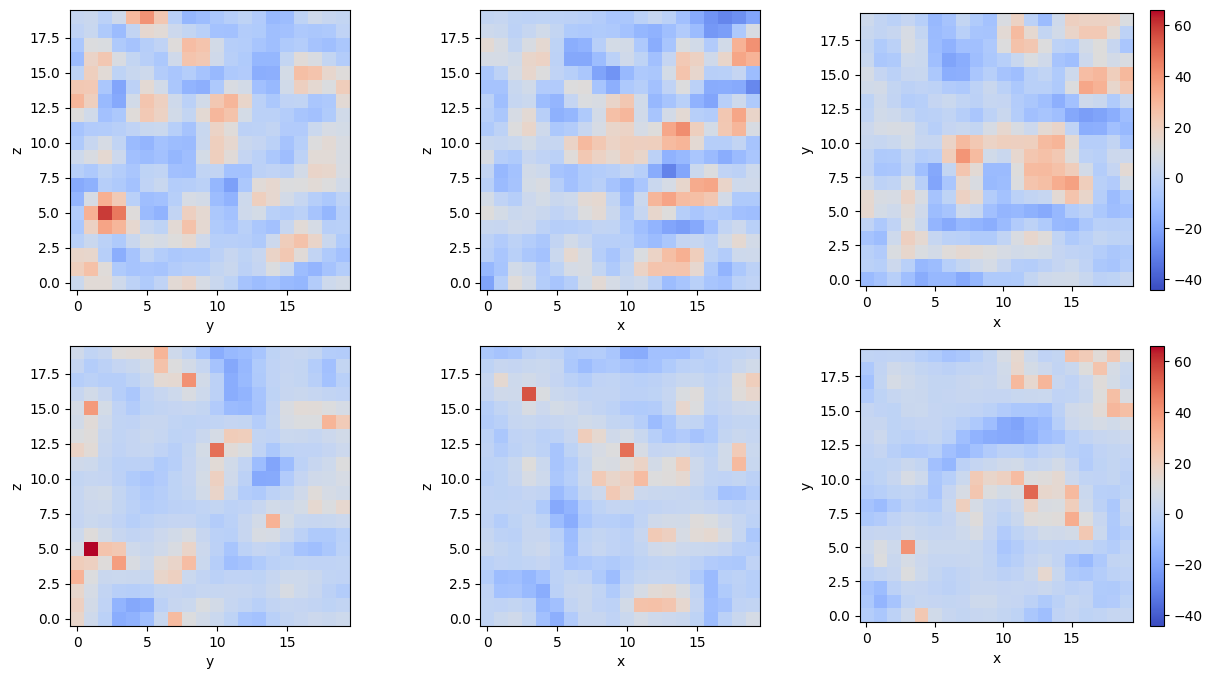

In [11]:
fig, axarr = plt.subplots(ncols=3, nrows=2, figsize=(15, 8))

norm = Normalize(vmin=ref_data[mask].min(), vmax=ref_data[mask].max())
for i, d in enumerate((ref_data, norm_data)):
    s = len(d) // 2
    a = len(d) // 2 - 10
    ax = axarr[i, 0]
    ax.imshow(d[s, a:-a, a:-a].T, origin='lower', cmap='coolwarm', norm=norm)
    ax.set_xlabel('y')
    ax.set_ylabel('z')
    ax = axarr[i, 1]
    ax.imshow(d[a:-a, s, a:-a].T, origin='lower', cmap='coolwarm', norm=norm)
    ax.set_xlabel('x')
    ax.set_ylabel('z')
    ax = axarr[i, 2]
    im = ax.imshow(d[a:-a, a:-a, s].T, origin='lower', cmap='coolwarm', norm=norm)
    plt.colorbar(im, ax=ax)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

### Distribution of values

Text(0, 0.5, 'Probability density')

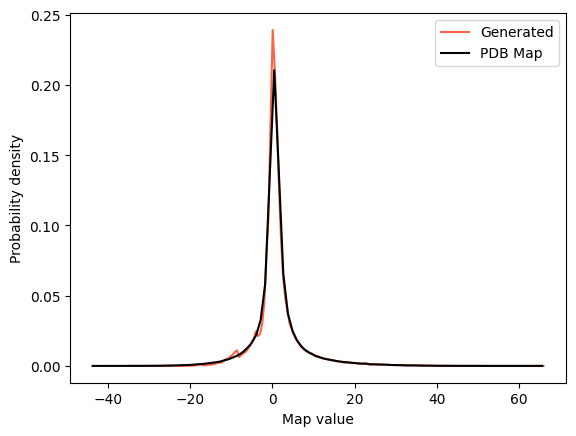

In [12]:
fig, ax = plt.subplots()
hist, bins = np.histogram(norm_data[mask].flatten(), bins=200, density=True)
ax.plot(edges_to_range(bins), hist, color='tomato', label='Generated')
hist, bins = np.histogram(ref_data[mask].flatten(), bins=100, density=True)
ax.plot(edges_to_range(bins), hist, color='black', label='PDB Map')
ax.legend()
ax.set_xlabel('Map value')
ax.set_ylabel('Probability density')


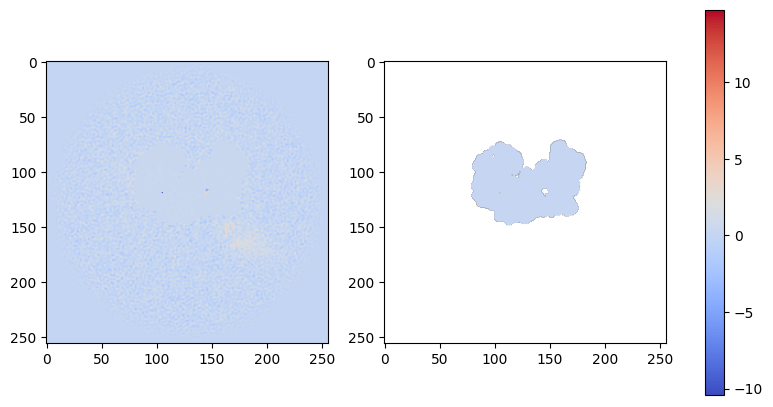

In [24]:
from matplotlib.colors import Normalize

norm = Normalize(vmin=ref_data.min(), vmax=ref_data.max())
fig, axarr = plt.subplots(ncols=2, figsize=(10, 5))
ax = axarr[0]
im = ax.imshow(ref_data[len(ref_data)//2, :, :], cmap='coolwarm', norm=norm)
ax = axarr[1]
ax.imshow(data[len(data)//2, :, :], cmap='coolwarm', norm=norm)
plt.colorbar(im, ax=axarr)

In [181]:
local_cc_unsharp = {}

for k, data in maps.items():
    for sharp in ('unsharp',):
        local_cc_unsharp[f'{k}_{sharp}'] = [
            linregress(data[m], ref_maps[sharp][m]).rvalue for m in local_shell_masks
        ]

In [207]:
vox_indices

array([ 4557150,  4557151,  4557152, ..., 12087699, 12087700, 12087701],
      shape=(533198,))

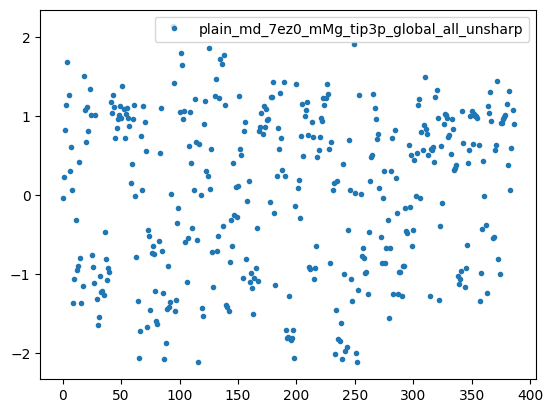

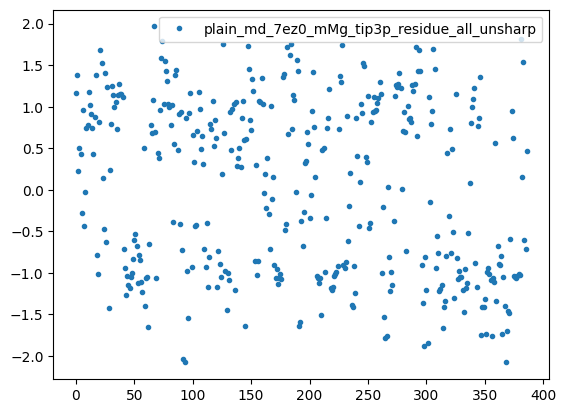

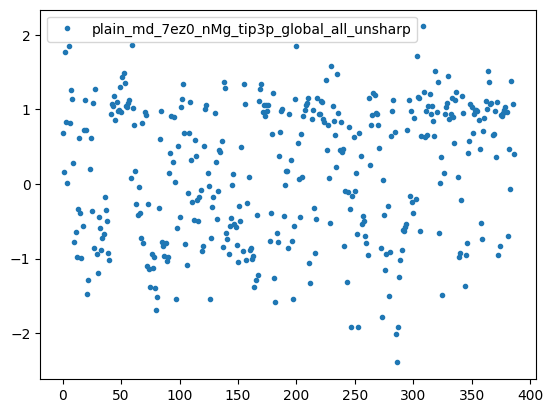

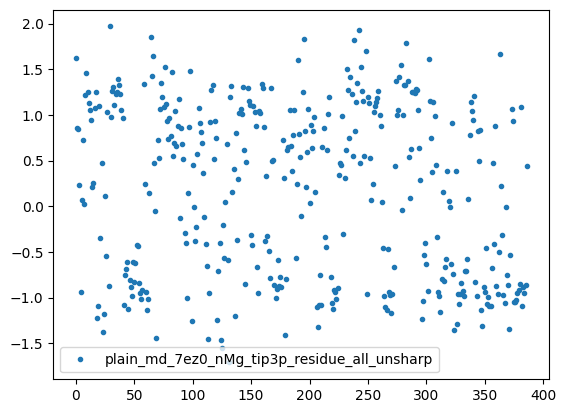

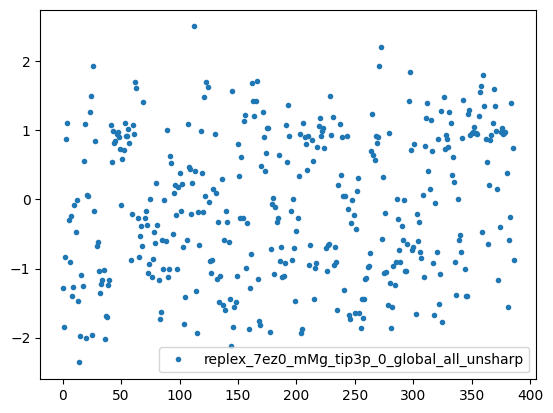

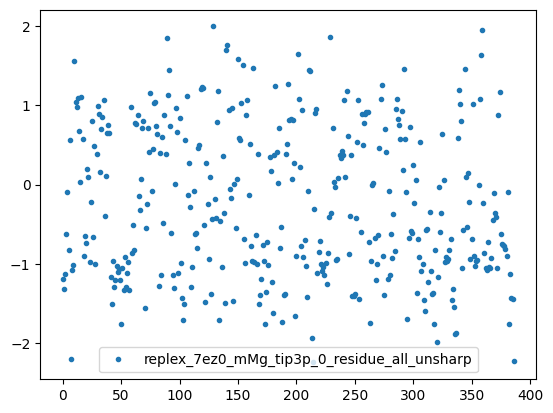

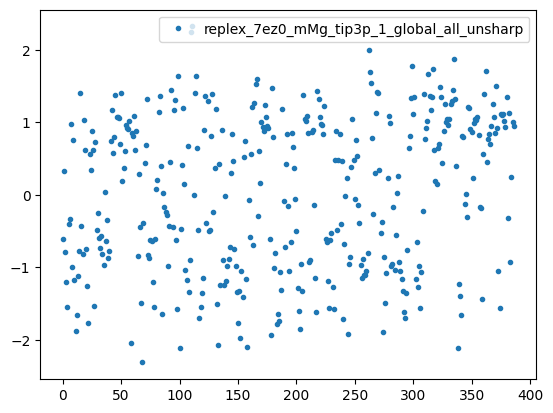

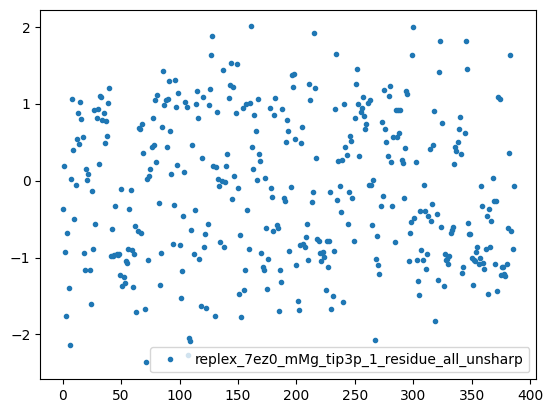

In [189]:
avg = np.mean(list(local_cc_unsharp.values()), axis=0)
std = np.std(list(local_cc_unsharp.values()), axis=0)

for k, v in local_cc_unsharp.items():
    plt.plot((np.array(v) - avg) / std, label=k, ls='none', marker='.')
    plt.legend()
    plt.show()